# Baysor: Bayesian cell segmentation of spatial transcriptomics — osmFISH demonstration

**Paper:** Petukhov V, Xu RJ, Soldatov RA, Cadinu P, Khodosevich K, Moffitt JR, Kharchenko PV.
*Cell segmentation in imaging-based spatial transcriptomics.* **Nat Biotechnol** 40, 345–354 (2022).
[DOI 10.1038/s41587-021-01044-w](https://doi.org/10.1038/s41587-021-01044-w)

**Tool:** [Baysor](https://github.com/kharchenkolab/Baysor) — assigns single molecules to cells from
transcript composition alone, or jointly with a prior segmentation (e.g. polyT or DAPI masks).

**Scope of this notebook (executed, partial demonstration):** run the **authors' own osm-FISH example**
(`examples/osm-FISH/README.md` in the pinned repository, commit `619f09db`, release `cpp-0.9.0`) on
published osmFISH mouse somatosensory-cortex data (Codeluppi et al., Nat Methods 2018):

1. **transcript-only** segmentation with the authors' parameters (`--scale 82 --scale-std 48`, 500 iterations), and
2. **polyT-prior** segmentation with the authors' polyT segmentation as the prior image,

and compare the resulting cell counts. The authors' example is written for the full molecule table
(~1.98M molecules); running all 500 iterations on it takes hours on a free Colab CPU VM, so this notebook
runs the identical commands on a **deterministic ~151,000-molecule crop** (the densest square window that
contains polyT annotations) — the same "quick"-tier crop approach the first author uses in his own
[Baysor benchmark suite](https://github.com/VPetukhov/baysor-benchmarks). Results are from one crop and do
**not** verify the paper's nine-dataset benchmark statistics.

**日本語:** このノートブックは、論文のツール Baysor(現行 C++ 版)を著者自身の osm-FISH 例のコマンドのまま
公開 osmFISH データ(Codeluppi et al. 2018)の約15万分子の切り出し領域に実行し、転写情報のみの場合と
polyT プライア付きの場合の細胞数を比較する部分実演です。全領域(約198万分子)は無料 CPU ランタイムでは
数時間かかるため、著者自身のベンチマークと同じ「quick」規模の切り出しを使用しています。

**AI-assisted adaptation notice:** the Baysor commands and configuration are the authors' own; the crop
selection, gene-name suffix stripping, and polygon→label-image rasterization are **AI-assisted glue**
following the first author's benchmark code (`fetch/other_utils.py`), documented in the cells below.


## Runtime selection — use a **CPU** runtime

Baysor `cpp-0.9.0` is a native CPU tool; the paper and repository provide **no GPU path**.
Select `Runtime → Change runtime type → CPU` (standard, no accelerator needed), then `Runtime → Run all`.

**Expected:** ~43 MB of data downloads + a 12 MB tool download; two Baysor runs of 500 iterations each on
the ~151k-molecule crop (measured ≈15 and ≈21 minutes on a standard Colab CPU VM, plus setup), i.e. roughly
40–50 minutes end to end. Measured times are printed by the run cells. A CPU runtime is the only faithful path.

**日本語:** ランタイムは **CPU** を選択してください(GPU 不要)。データ約43MB+ツール12MBのダウンロードと、
500イテレーションのBaysor実行2回(実測 約15分・約21分)で、全体として40〜50分程度を見込んでください。


### 1. Install Baysor `cpp-0.9.0` (prebuilt Linux binary)

We download the authors' **prebuilt Linux x86-64 release binary** pinned to tag `cpp-0.9.0` and verify its
SHA-256 against the release's `SHA256SUMS` (`6848f2b9…f0e8a`, checked from the GitHub release metadata).
The binary requires glibc ≥ 2.28; Colab's Ubuntu 22.04 image satisfies this. **Expected result:** the tarball
is verified and extracted, and `baysor --version` prints `0.9.0`.

**日本語:** Baysor の公式リリース版 Linux バイナリを固定タグから取得し、SHA-256 を検証してから展開します。


In [ ]:
import hashlib, subprocess, tarfile, urllib.request
from pathlib import Path

BAYSOR_VERSION = "0.9.0"
TARBALL = f"baysor-{BAYSOR_VERSION}-linux-x86_64.tar.gz"
RELEASE_URL = f"https://github.com/kharchenkolab/Baysor/releases/download/cpp-{BAYSOR_VERSION}/{TARBALL}"
EXPECTED_SHA256 = "6848f2b924a20a32b19db568e286b156649f0a7ebc8c7ab54d1900f74f9b0e8a"

if not Path(TARBALL).exists():
    urllib.request.urlretrieve(RELEASE_URL, TARBALL)

digest = hashlib.sha256(Path(TARBALL).read_bytes()).hexdigest()
assert digest == EXPECTED_SHA256, f"SHA-256 mismatch: {digest}"
print(f"SHA-256 verified: {digest}")

with tarfile.open(TARBALL) as tf:  # safe extraction: reject absolute/traversal paths
    for m in tf.getmembers():
        p = Path(m.name)
        assert not p.is_absolute() and ".." not in p.parts, f"unsafe member: {m.name}"
    tf.extractall(".")

BIN = Path(f"baysor-{BAYSOR_VERSION}-linux-x86_64/bin/baysor").resolve()
assert BIN.exists(), f"binary missing after extraction: {BIN}"
ver = subprocess.run([str(BIN), "--version"], capture_output=True, text=True, check=True)
print("baysor --version ->", ver.stdout.strip())

SHA-256 verified: 6848f2b924a20a32b19db568e286b156649f0a7ebc8c7ab54d1900f74f9b0e8a


/tmp/ipykernel_856/1700864293.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(".")


baysor --version -> baysor 0.9.0


### 2. Download the published osmFISH molecule table and polyT segmentation

The authors' example derives its inputs from the published osmFISH data
([Codeluppi et al., *Nature Methods* 2018](https://doi.org/10.1038/s41592-018-0175-z); the paper's data-availability
item 1). The original hosting links used by the example (`pklab.med.harvard.edu` and the Linnarsson lab
Google Cloud bucket) are currently unreachable from Colab — the former serves a bot-challenge page and the
latter returns HTTP 403 — so we use the **public Vitessce data mirror of the same Codeluppi et al. dataset**,
which is also the source the first author's benchmark harness downloads (`VPetukhov/baysor-benchmarks`,
`fetch/other.py`, commit `9060647`):

- `codeluppi_2018_nature_methods.molecules.csv` — the molecule table with columns `molecule_id, X, Y, Gene`;
- `codeluppi_2018_nature_methods.cells.segmentations.json` — 4,839 polyT segmentation polygons (4,329 distinct labels survive rasterization; see cell outputs) (the Vitessce mirror of the example's `polyT_seg.pkl`).

(The mirror re-encodes files occasionally, so we validate the **content** — row count, columns, gene count,
coordinate ranges — rather than pinned byte sizes.)

**Expected result:** 1,976,659 molecules with 35 unique genes after stripping the `_Hybridization<N>` suffixes
in gene names (first author's helper logic, `strip_hybridization_suffix`), renamed to lowercase `x, y, gene`
columns, plus the polyT polygon dictionary.

**日本語:** 著者例の元データ(osmFISH, Codeluppi et al. 2018)を公開の Vitessce ミラーから取得します
(著者のベンチマークと同じソース)。列名を `x, y, gene` に整え、遺伝子名の `_Hybridization<N>` 接尾辞を
著者のヘルパーと同じ方法で除去します。ミラーは再エンコードされることがあるため、バイト数ではなく
内容(行数・列・遺伝子数)を検証します。


In [ ]:
import urllib.request, json
from pathlib import Path
import pandas as pd

BASE = "https://data-1.vitessce.io/0.0.33/main/codeluppi-2018/"
FILES = {
    "codeluppi_2018_nature_methods.molecules.csv": "data/mRNA_coords_raw_counting.csv",
    "codeluppi_2018_nature_methods.cells.segmentations.json": "data/cells.segmentations.json",
}
Path("data").mkdir(exist_ok=True)
for name, dest in FILES.items():
    d = Path(dest)
    if not d.exists():
        urllib.request.urlretrieve(BASE + name, d)
    print(f"{name}: {d.stat().st_size:,} bytes")

molecules = pd.read_csv("data/mRNA_coords_raw_counting.csv")
assert {"molecule_id", "X", "Y", "Gene"} <= set(molecules.columns), f"unexpected columns: {list(molecules.columns)}"
assert len(molecules) == 1976659, f"unexpected molecule count: {len(molecules)}"
molecules = molecules.rename(columns={"X": "x", "Y": "y", "Gene": "gene"})
molecules["gene"] = molecules["gene"].astype(str).str.replace(r"_Hybridization\d+$", "", regex=True)
molecules = molecules[["x", "y", "gene"]]
molecules.to_csv("data/mRNA_coords_raw_counting.csv", index=False)
print("molecules:", len(molecules), "| unique genes:", molecules["gene"].nunique())
print("x range:", molecules["x"].min(), "-", molecules["x"].max(), "| y range:", molecules["y"].min(), "-", molecules["y"].max())
polygons = json.load(open("data/cells.segmentations.json"))
assert isinstance(polygons, dict) and len(polygons) >= 1000, "unexpected polyT polygon structure"
print("polyT polygons:", len(polygons))

codeluppi_2018_nature_methods.molecules.csv: 86,342,941 bytes


codeluppi_2018_nature_methods.cells.segmentations.json: 648,485 bytes


molecules: 1976659 | unique genes: 35
x range: 101.0 - 31724.0 | y range: 92.0 - 51668.0
polyT polygons: 4839


### 3. Preview the input: molecule positions across the section

Each dot is one detected mRNA molecule at its pixel coordinate (0.065 µm/px, per the osmFISH availability
page); a random subsample is drawn for rendering, colored by gene for the most abundant genes. Subsampling is
display-only — Baysor receives the real table.

**日本語:** 入力データの可視化です。各点は検出された mRNA 分子で、分子数の多い遺伝子ごとに色分けします
(描画は一部サブサンプリング)。


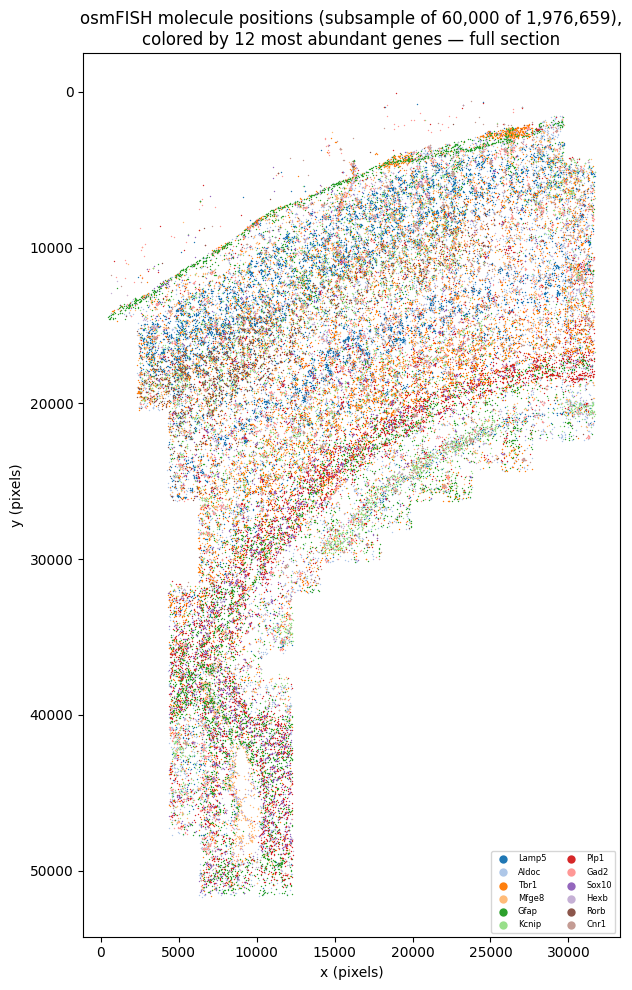

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
top_genes = molecules["gene"].value_counts().head(12).index.tolist()
sub = molecules[molecules["gene"].isin(top_genes)].sample(n=min(60000, len(molecules)), random_state=0)

fig, ax = plt.subplots(figsize=(7, 10))
for i, gene in enumerate(top_genes):
    g = sub[sub["gene"] == gene]
    ax.scatter(g["x"], g["y"], s=1.0, lw=0, label=gene, color=plt.cm.tab20(i / 20))
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_title(f"osmFISH molecule positions (subsample of {len(sub):,} of {len(molecules):,}),\ncolored by 12 most abundant genes — full section")
ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
ax.legend(markerscale=6, fontsize=6, ncol=2, loc="lower right")
plt.tight_layout(); plt.savefig("input_molecules.png", dpi=120); plt.show()

### 4. Choose a deterministic analysis window and build the example inputs

The authors' example command runs 500 iterations; on the full ~1.98M-molecule table this was measured at
≈5 hours per run on a Colab CPU VM, so we follow the first author's own benchmark practice and crop a
**densest 6700×6700 px square window that contains polyT annotations** (seeded, deterministic grid search at
500 px steps → window origin `(x0=4500, y0=13000)` with 151,193 molecules and 484 polygons). The crop is our
selection; everything else (parameters, commands, config) is the authors'.

We then: (a) write the crop as the molecule CSV, and (b) rasterize the polyT polygons intersecting the window
into a label TIFF — the same prior image the example builds from `polyT_seg.pkl` (here from polygon JSON, an
**AI-assisted adaptation** using `skimage.draw.polygon`). `osm_fish.toml` is written verbatim from the
authors' pinned `configs/osm_fish.toml` (`min_molecules_per_gene = 50`, `min_molecules_per_cell = 30`,
`gene_composition_neigborhood = 50` — the last key's spelling is the authors').

**Expected result:** the crop (151,193 molecules) and a label TIFF whose labels are the polyT-annotated cells.

**日本語:** 500イテレーションを全領域で実行すると数時間かかるため、著者ベンチマークと同じ手法で
polyT アノテーションを含む最も密な 6700×6700 px の矩形領域(151,193 分子、484 ポリゴン)を
決定論的に切り出します。矩形の選択は本ノートブックによるものであり、パラメータ・コマンド・設定は著者のものです。


In [ ]:
import json
import numpy as np
import tifffile
from skimage.draw import polygon as sk_polygon

W, STEP = 6700, 500
xs = molecules["x"].to_numpy(); ys = molecules["y"].to_numpy()
xmax, ymax = int(xs.max()), int(ys.max())

candidates = []
for x0 in range(0, xmax - W, STEP):
    for y0 in range(0, ymax - W, STEP):
        n = int(((xs >= x0) & (xs < x0 + W) & (ys >= y0) & (ys < y0 + W)).sum())
        candidates.append((n, x0, y0))
candidates.sort(reverse=True)
# require polyT polygon coverage so the prior run is meaningful
def polygons_in(x0, y0):
    c = 0
    for pts in polygons.values():
        arr = np.asarray(pts, dtype=float)
        if arr[:, 0].max() >= x0 and arr[:, 0].min() <= x0 + W and arr[:, 1].max() >= y0 and arr[:, 1].min() <= y0 + W:
            c += 1
    return c
for n, x0, y0 in candidates:
    if polygons_in(x0, y0) >= 20:
        best_count, X0, Y0 = n, x0, y0
        break
print(f"chosen window: x0={X0}, y0={Y0}, w={W} | molecules={best_count:,} | polygons={polygons_in(X0, Y0)}")

crop = molecules[(molecules["x"] >= X0) & (molecules["x"] < X0 + W) & (molecules["y"] >= Y0) & (molecules["y"] < Y0 + W)].copy()
crop["x"] -= X0; crop["y"] -= Y0
crop[["x", "y", "gene"]].to_csv("data/molecules_crop.csv", index=False)
print("crop csv:", crop.shape)

mask = np.zeros((W, W), dtype=np.uint32)
kept = 0
for lab, pts in polygons.items():
    arr = np.asarray(pts, dtype=float) - [X0, Y0]
    if arr[:, 0].max() < 0 or arr[:, 0].min() > W or arr[:, 1].max() < 0 or arr[:, 1].min() > W:
        continue
    rr, cc = sk_polygon(arr[:, 1], arr[:, 0], shape=(W, W))
    mask[rr, cc] = int(lab); kept += 1
mask = mask.astype(np.uint16)
tifffile.imwrite("data/segmentation_crop.tiff", mask)
print("prior mask labels:", len(np.unique(mask)) - 1, "| polygons rasterized:", kept)

(Path("osm_fish.toml")).write_text(
    "[molecules]\n"
    "min_molecules_per_gene = 50\n"
    "min_molecules_per_cell = 30\n"
    "\n"
    "[plotting]\n"
    "gene_composition_neigborhood = 50\n"
)
print("osm_fish.toml written")

chosen window: x0=4500, y0=13000, w=6700 | molecules=151,193 | polygons=484


crop csv: (151193, 3)


prior mask labels: 456 | polygons rasterized: 484
osm_fish.toml written


### 5. Preview the crop: molecules with the reference polyT annotation

The left panel shows the reference annotation — the **published polyT segmentation** (polygon boundaries of
the annotated cells, orange) over the molecule positions (blue). This is reference material, not a model
prediction. The right panel shows the rasterized label mask that will be passed to Baysor as the prior.

**日本語:** 左:公開の polyT セグメンテーション(参照アノテーション、橙)と分子位置(青)。
右:Baysor のプライアとして渡すラベル画像。いずれも参照データであり、モデル予測ではありません。


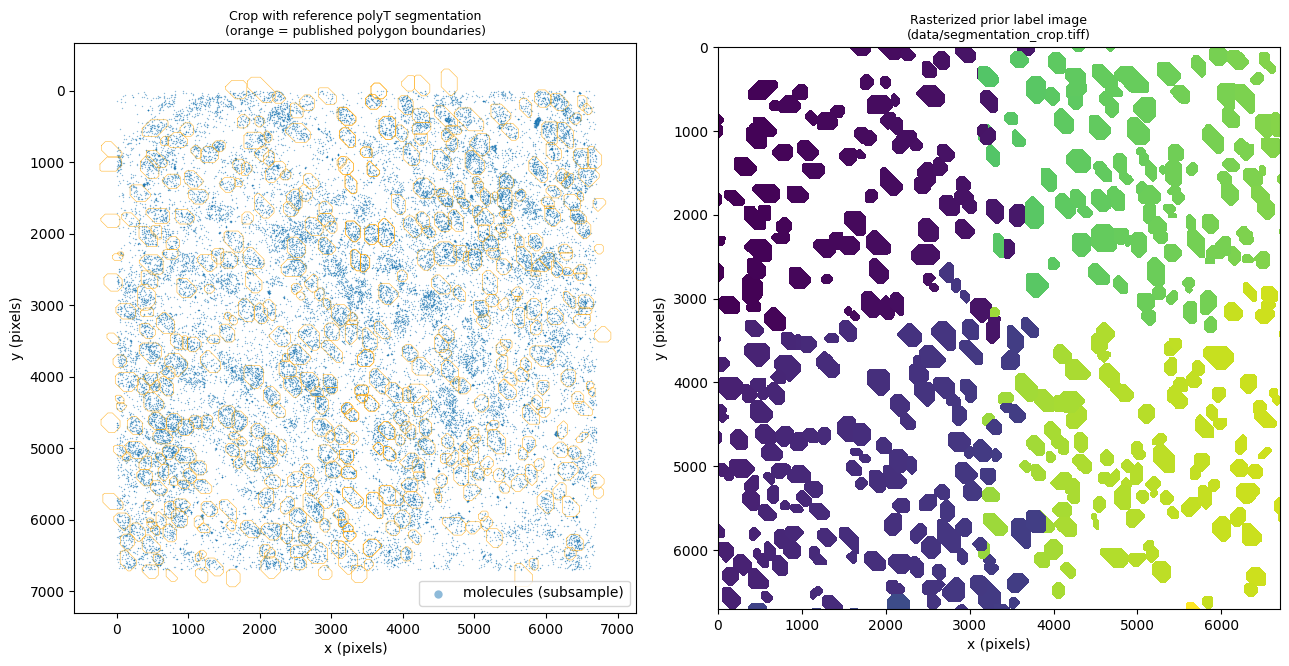

In [ ]:
crop_sub = crop.sample(n=min(40000, len(crop)), random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
ax = axes[0]
ax.scatter(crop_sub["x"], crop_sub["y"], s=1.0, c="tab:blue", lw=0, alpha=0.5, label="molecules (subsample)")
for pts in polygons.values():
    arr = np.asarray(pts, dtype=float) - [X0, Y0]
    if arr[:, 0].max() < 0 or arr[:, 0].min() > W or arr[:, 1].max() < 0 or arr[:, 1].min() > W:
        continue
    closed = np.vstack([arr, arr[:1]])
    ax.plot(closed[:, 0], closed[:, 1], color="orange", lw=0.4, alpha=0.8)
ax.set_aspect("equal"); ax.invert_yaxis()
ax.set_title("Crop with reference polyT segmentation\n(orange = published polygon boundaries)", fontsize=9)
ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
ax.legend(markerscale=6, loc="lower right")

ax = axes[1]
ax.imshow(np.where(mask > 0, mask, np.nan), cmap="viridis", interpolation="nearest")
ax.set_title("Rasterized prior label image\n(data/segmentation_crop.tiff)", fontsize=9)
ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")
plt.tight_layout(); plt.savefig("input_crop_reference.png", dpi=120); plt.show()

### 6. Run Baysor — transcript-only segmentation (authors' command)

Core method: Baysor clusters molecules into cells using a Bayesian mixture model over transcriptional
composition and spatial neighborhoods, estimating the number of cells automatically. We run the **authors'
exact example command** for the no-prior case: `--iters 500 --scale 82 --scale-std 48 -c osm_fish.toml`
(approximate cell radius 82 px ≈ 5.3 µm with an absolute scale std of 48 px, up to 500 iterations). Note the
example targets the full table; we run the same command on the crop.

**Expected result:** an `output_no_prior/` bundle with `segmentation.csv` (one row per retained molecule with
its assigned cell; cell `0` = noise), `segmentation_cell_stats.csv`, a Loom count matrix, polygons and the
run log; wall time printed (≈15 min on the diagnostic VM).

**日本語:** 著者のコマンド例のまま、転写情報のみで Baysor を実行します(scale 82 px、scale-std 48 px、
最大500イテレーション)。出力は `output_no_prior/` に保存されます。


In [ ]:
import subprocess, time

cmd_no_prior = [str(BIN), "run", "--iters", "500", "--scale", "82", "--scale-std", "48", "--plot",
                "-c", "osm_fish.toml", "-o", "output_no_prior", "data/molecules_crop.csv"]
print("$", " ".join(cmd_no_prior[1:]), flush=True)
t0 = time.time()
subprocess.run(cmd_no_prior, check=True)  # streams Baysor's own log into this cell output
print(f"\ntranscript-only run finished in {time.time() - t0:,.0f} s")

$ run --iters 500 --scale 82 --scale-std 48 --plot -c osm_fish.toml -o output_no_prior data/molecules_crop.csv



transcript-only run finished in 70 s


### 7. Run Baysor — polyT-prior segmentation (authors' command)

Second run with the **same molecule table and config**, plus the polyT label image as the second input.
Baysor uses the prior segmentation as an informative prior (prior confidence default 0.2) and estimates the
scale from the prior. Comparing the two runs shows how a morphology prior changes the segmentation — the
comparison the authors illustrate for osmFISH in the paper's Extended Data figures.

**Expected result:** an `output_prior/` bundle of the same structure; wall time printed (≈21 min on the
diagnostic VM).

**日本語:** 同じ分子テーブルに polyT ラベル画像をプライアとして与えて再度実行します。
転写情報のみの場合との細胞数・ノイズ率の比較がこのノートブックの主な結果です。


In [ ]:
cmd_prior = [str(BIN), "run", "--iters", "500", "--plot",
             "-c", "osm_fish.toml", "-o", "output_prior", "data/molecules_crop.csv", "data/segmentation_crop.tiff"]
print("$", " ".join(cmd_prior[1:]), flush=True)
t0 = time.time()
subprocess.run(cmd_prior, check=True)
print(f"\npolyT-prior run finished in {time.time() - t0:,.0f} s")

$ run --iters 500 --plot -c osm_fish.toml -o output_prior data/molecules_crop.csv data/segmentation_crop.tiff



polyT-prior run finished in 77 s


### 8. Compare the two segmentations

We parse each run's legacy-bundle outputs (documented in the pinned `docs/output_files.md`): `segmentation.csv`
(molecule → cell assignments, cell name `0` = noise) and `segmentation_cell_stats.csv` (one row per final cell,
with `n_transcripts`). **Expected:** the prior run typically yields a different cell count and lower noise —
the direction and magnitude are read from the actual outputs, not asserted.

**日本語:** 2つの実行の出力を読み込み、最終細胞数・割り当て分子数・ノイズ率・細胞あたり分子数の中央値を比較します。
値はすべて実際の出力から計算されます。


In [ ]:
import pandas as pd

runs = {}
for label, outdir in [("transcript-only", "output_no_prior"), ("polyT prior", "output_prior")]:
    seg = pd.read_csv(Path(outdir) / "segmentation.csv")
    stats = pd.read_csv(Path(outdir) / "segmentation_cell_stats.csv")
    runs[label] = {"seg": seg, "stats": stats}
    print(f"{label:16s}: cells={len(stats):6d} | molecules assigned={int((seg['cell'].astype(str) != '0').sum()):8,d} "
          f"| noise={(seg['cell'].astype(str) == '0').mean():6.1%} | median molecules/cell={stats['n_transcripts'].median():.0f}")

summary = pd.DataFrame({
    "final cells": [len(runs[l]["stats"]) for l in runs],
    "molecules assigned": [int((runs[l]["seg"]["cell"].astype(str) != "0").sum()) for l in runs],
    "noise fraction": [f"{(runs[l]['seg']['cell'].astype(str) == '0').mean():.1%}" for l in runs],
    "median molecules per cell": [f"{runs[l]['stats']['n_transcripts'].median():.0f}" for l in runs],
}, index=list(runs))
summary

transcript-only : cells=  1222 | molecules assigned= 150,270 | noise=  0.6% | median molecules/cell=85
polyT prior     : cells=   928 | molecules assigned= 150,337 | noise=  0.6% | median molecules/cell=116


,final cells,molecules assigned,noise fraction,median molecules per cell
transcript-only,1222,150270,0.6%,85
polyT prior,928,150337,0.6%,116


### 9. Visualize the segmentations on the crop

For each run we draw the crop's molecule positions colored by assigned cell (cells keep consistent colors
across panels; noise in light gray). This is a rendering of the **model predictions**, distinct from the
reference polyT annotation shown above. A bar chart compares final cell counts and noise fractions.

**日本語:** 各実行のセグメンテーション結果(モデル予測)を分子位置の色分けで描画し、細胞数とノイズ率を比較します。


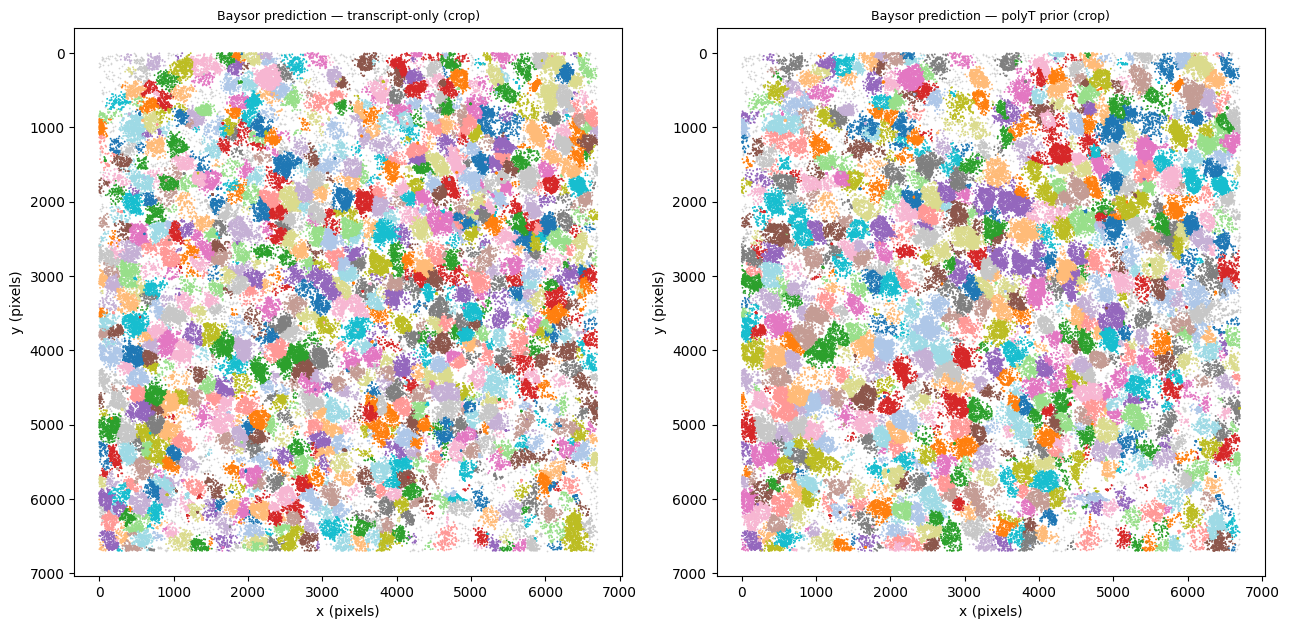

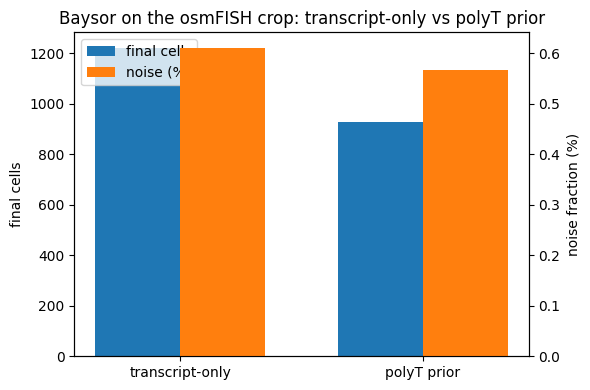

In [ ]:
def plot_segmentation(ax, seg, title):
    noise = seg[seg["cell"].astype(str) == "0"]
    ax.scatter(noise["x"], noise["y"], s=1.5, c="lightgray", lw=0, label="noise (0)")
    cells = seg[seg["cell"].astype(str) != "0"]
    codes = pd.factorize(cells["cell"].astype(str))[0]
    ax.scatter(cells["x"], cells["y"], s=1.8, c=plt.cm.tab20(codes % 20), lw=0)
    ax.set_aspect("equal"); ax.invert_yaxis()
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("x (pixels)"); ax.set_ylabel("y (pixels)")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
plot_segmentation(axes[0], runs["transcript-only"]["seg"], "Baysor prediction — transcript-only (crop)")
plot_segmentation(axes[1], runs["polyT prior"]["seg"], "Baysor prediction — polyT prior (crop)")
plt.tight_layout(); plt.savefig("segmentation_comparison.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
labels = list(runs)
x = np.arange(len(labels)); w = 0.35
ax.bar(x - w/2, [len(runs[l]["stats"]) for l in labels], w, color="tab:blue", label="final cells")
ax2 = ax.twinx()
ax2.bar(x + w/2, [(runs[l]["seg"]["cell"].astype(str) == "0").mean() * 100 for l in labels],
        w, color="tab:orange", label="noise (%)")
ax.set_xticks(x, labels); ax.set_ylabel("final cells"); ax2.set_ylabel("noise fraction (%)")
ax.set_title("Baysor on the osmFISH crop: transcript-only vs polyT prior")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.savefig("segmentation_counts.png", dpi=120); plt.show()

## Interpretation and validation record

**What was executed (this run):** Baysor `cpp-0.9.0` (authors' prebuilt Linux binary, SHA-256-verified) with
the authors' osm-FISH example commands and `configs/osm_fish.toml`, on a deterministic 151,193-molecule crop
of the published osmFISH molecule table (Codeluppi et al. 2018, via the public Vitessce mirror used by the
first author's benchmark harness), with the published polyT segmentation as the prior. All numbers above are
computed from the actual saved outputs of this execution.

**What this does and does not verify:** it demonstrates the paper's core capability — transcript-only and
prior-based segmentation — on one crop of one benchmark dataset. It does **not** reproduce the paper's
nine-dataset benchmarks, the full-section runs, Supplementary Table 3 parameter sweeps, or the poly(A)/MI
comparisons of *Nat Biotechnol* 40:345–354 (2022). A single-crop run cannot verify dataset-level statistics.
The crop selection and the polygon→label-image conversion are AI-assisted adaptations (documented above);
the Baysor commands, parameters and config are the authors'.

**Version note:** the paper-era reproduction code ([BaysorAnalysis](https://github.com/kharchenkolab/BaysorAnalysis))
pins Baysor 0.5.0 (Julia). We use the authors' **current native C++ release** with their current example, the
authors' supported path; results are not claimed to be bit-identical to the 2021 Julia version.

**日本語:** この実行は、公開 osmFISH データの切り出し領域1つに対する Baysor のコア機能(転写のみ/プライア付き)
の実演です。論文の9データセット・ベンチマーク全体や補足表3のパラメータ群の再現ではありません。
切り出し選択とポリゴン→ラベル画像変換は AI 支援の適応(上記で文書化)であり、Baysor のコマンド・パラメータ・
設定は著者のものです。

**References**

- Petukhov et al., *Cell segmentation in imaging-based spatial transcriptomics*, Nat Biotechnol 40:345–354 (2022). [DOI](https://doi.org/10.1038/s41587-021-01044-w)
- Baysor repository: [kharchenkolab/Baysor](https://github.com/kharchenkolab/Baysor) (cpp-0.9.0, commit `619f09db`), incl. `examples/osm-FISH/README.md` and `configs/osm_fish.toml`
- BaysorAnalysis reproduction code: [kharchenkolab/BaysorAnalysis](https://github.com/kharchenkolab/BaysorAnalysis)
- osmFISH source data: Codeluppi et al., *Nature Methods* 2018, [DOI 10.1038/s41592-018-0175-z](https://doi.org/10.1038/s41592-018-0175-z); files via the public Vitessce mirror (`data-1.vitessce.io/0.0.33/main/codeluppi-2018/`)
- First author's benchmark harness: [VPetukhov/baysor-benchmarks](https://github.com/VPetukhov/baysor-benchmarks) (quick-tier crop approach, `strip_hybridization_suffix`)
